In [2]:
#importing basic necessory libraries here
import pandas as pd
import numpy as np

In [3]:
#loading data here
df=pd.read_csv(r'F:\Internshala\Internshala projects\InternshalaProjectMLUsingPython\eBay.csv')
df

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Personalized_Recommendation_Frequency,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Personalized_Recommendation_Frequency,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
0,2023/06/07 11:44:55 AM GMT+5:30,32,Prefer not to say,Multiple times a week,Groceries and Gourmet Food;Home and Kitchen,Sometimes,Rarely,categories,Multiple pages,5,...,Yes,Never,Yes,5,Yes,1,1,Customer service,.,819284
1,2023/06/07 9:28:09 AM GMT+5:30,47,Female,Multiple times a week,Groceries and Gourmet Food;Beauty and Personal...,No,Few times a month,NaN,First page,5,...,Yes,Never,Sometimes,2,Yes,4,4,User-friendly website/app interface,Shipping speed and reliability,599249
2,2023/06/05 10:09:03 PM GMT+5:30,50,Female,Once a month,Groceries and Gourmet Food;Beauty and Personal...,Sometimes,Multiple times a day,categories,Multiple pages,1,...,Yes,Rarely,Sometimes,1,Sometimes,4,2,Customer service,Reducing packaging waste,432245
3,2023/06/07 5:58:12 PM GMT+5:30,6,Others,Once a month,Groceries and Gourmet Food;Beauty and Personal...,No,Rarely,others,Multiple pages,1,...,No,Heavily,No,2,Yes,4,4,Product recommendations,Irrelevant product suggestions,476517
4,2023/06/07 11:46:52 AM GMT+5:30,61,Male,Once a week,Groceries and Gourmet Food;Clothing and Fashion,Yes,Rarely,NaN,Multiple pages,5,...,No,Never,Yes,2,No,3,2,Product recommendations,Shipping speed and reliability,894659
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,2023/06/05 1:27:08 PM GMT+5:30,55,Others,Few times a month,Groceries and Gourmet Food;Beauty and Personal...,Sometimes,Few times a month,others,First page,3,...,No,Moderately,Sometimes,5,No,3,3,All the above,Add more familiar brands to the list,668087
796,2023/06/12 3:42:05 PM GMT+5:30,57,Female,Once a month,others,Sometimes,Few times a month,others,First page,2,...,Yes,Heavily,Yes,5,Yes,5,2,User-friendly website/app interface,Shipping speed and reliability,920085
797,2023/06/10 10:49:42 AM GMT+5:30,63,Male,Multiple times a week,Clothing and Fashion;Home and Kitchen;others,Yes,Rarely,NaN,Multiple pages,4,...,No,Never,Yes,1,Sometimes,4,1,Customer service,Shipping speed and reliability,278493
798,2023/06/12 3:38:48 PM GMT+5:30,53,Female,Less than once a month,Groceries and Gourmet Food;Beauty and Personal...,Sometimes,Multiple times a day,categories,Multiple pages,4,...,Yes,Never,No,2,Sometimes,4,3,.,User interface,675854


### Data cleaning and Preparation

In [4]:
#removing dupicate rows
df=df.drop_duplicates()

In [5]:
#removing duplicated based on time stamp,age and gender(making sure no same user answered same time)
df=df.drop_duplicates(subset=["Timestamp", "age", "Gender"])

In [6]:
#replacing null product search method with unknown
df["Product_Search_Method"]=(df["Product_Search_Method"].str.strip().str.lower().fillna("unknown"))

In [7]:
#making all product search uniformity in letter 'case'
df["Product_Search_Method"]=df["Product_Search_Method"].replace({"Keyword":"keyword","Filter":"filter"})

In [8]:
#Cleaning column names
df.columns=(df.columns
      .str.strip()                 # remove leading/trailing spaces
      .str.replace(" ", "_")       # replace spaces with underscores
      .str.replace("__+", "_", regex=True)  # remove double underscores
)

In [9]:
#dropping unnecessory duplicated categorical 'Personalized_Recommendation_Frequency' column
df = df.loc[:, ~df.columns.duplicated(keep='last')]

In [10]:
#making rating related columns to numeric if they are not.
rating_cols=["Customer_Reviews_Importance","Shopping_Satisfaction","Rating_Accuracy"]

for col in rating_cols:
    df[col]=pd.to_numeric(df[col],errors="coerce")

In [11]:
#converting Timestamp and age to proper types
df["Timestamp"]=pd.to_datetime(df["Timestamp"],errors="coerce")
df["age"]=pd.to_numeric(df["age"],errors="coerce")

C:\Users\PrdiAcerAspireE1-531\AppData\Local\Temp\ipykernel_12132\3544315273.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Timestamp"]=pd.to_datetime(df["Timestamp"],errors="coerce")


In [12]:
cols=["Service_Appreciation","Improvement_Areas"]
df[cols]=df[cols].replace(".", "Not Applicable")

In [13]:
print(df.info())
print(df.isna().sum())
print(df)

<class 'pandas.core.frame.DataFrame'>
Index: 798 entries, 0 to 799
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype                    
---  ------                                 --------------  -----                    
 0   Timestamp                              798 non-null    datetime64[ns, UTC-05:30]
 1   age                                    798 non-null    int64                    
 2   Gender                                 798 non-null    object                   
 3   Purchase_Frequency                     798 non-null    object                   
 4   Purchase_Categories                    798 non-null    object                   
 5   Browsing_Frequency                     798 non-null    object                   
 6   Product_Search_Method                  798 non-null    object                   
 7   Search_Result_Exploration              798 non-null    object                   
 8   Customer_Reviews_Importance        

###### There are no null values in both categorical and non categorical columns so we can explore data further now

### Descriptive Behavior Analysis

#### ● Summarizing customer demographics (age, gender distribution).

##### ● age demographics

In [14]:
#getting minimum and maximum age for 'age grouping'.
print(df['age'].min())
print(df['age'].max())

3
67


Count of customers of different age groups as fallows

Number of customers below age 18 :  179
Number of customers in 19-25 age group :  86
Number of customers in 26-40 age group :  164
Number of customers in 41-60 age group :  266
Number of customers above age group of 60 :  84


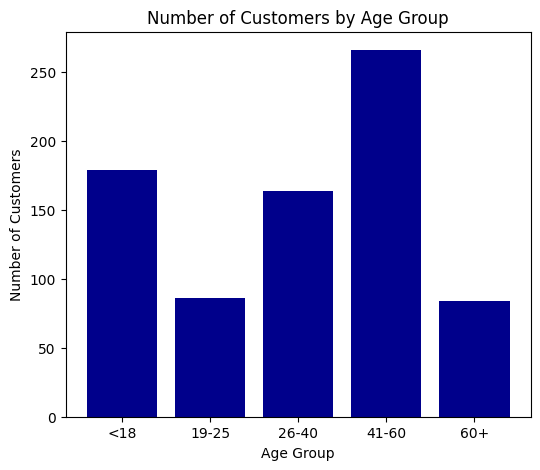



Percentage wise distribution of different age gouped customers as fallows

Percentage of customers below age 18 : 22.43
Percentae of customers in 19-25 age group : 10.78
Percentage of customers in 26-40 age group : 20.55
Percentage of customers in 41-60 age group : 33.33
Percentage of customers above age group of 60 : 10.53


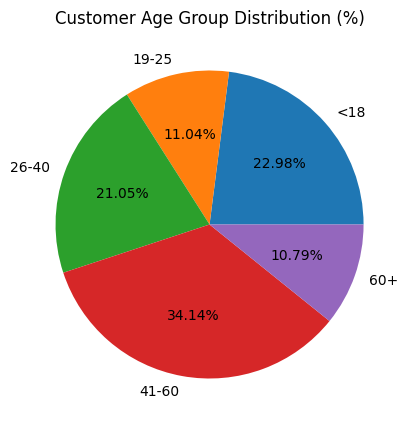

In [15]:
print('Count of customers of different age groups as fallows\n')
cust_below_18=(df['age']<18).sum()
print('Number of customers below age 18 : ',cust_below_18)
cust_bw_19to25=((df['age']>18) & (df['age']<=25)).sum()
print('Number of customers in 19-25 age group : ',cust_bw_19to25)
cust_bw_26to40=((df['age']>26) & (df['age']<=40)).sum()
print('Number of customers in 26-40 age group : ',cust_bw_26to40)
cust_bw_41to60=((df['age']>40) & (df['age']<=60)).sum()
print('Number of customers in 41-60 age group : ',cust_bw_41to60)
cust_above_60=(df['age']>60).sum()
print('Number of customers above age group of 60 : ',cust_above_60)

import matplotlib.pyplot as plt

# Age groups and counts
age_groups=['<18', '19-25', '26-40', '41-60', '60+']
counts=[cust_below_18,cust_bw_19to25,cust_bw_26to40,cust_bw_41to60,cust_above_60]

plt.figure(figsize=(6,5))
plt.bar(age_groups, counts, color='darkblue')
plt.title("Number of Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.show()


total_customers=df['age'].count()

cust_below_18_percent=round(((cust_below_18/total_customers)*100),2)
cust_bw_19to25_percent=round(((cust_bw_19to25/total_customers)*100),2)
cust_bw_26to40_percent=round(((cust_bw_26to40/total_customers)*100),2)
cust_bw_41to60_percent=round(((cust_bw_41to60/total_customers)*100),2)
cust_above_60_percent=round(((cust_above_60/total_customers)*100),2)

print('\n\nPercentage wise distribution of different age gouped customers as fallows\n')
print(f'Percentage of customers below age 18 : {cust_below_18_percent}')
print(f'Percentae of customers in 19-25 age group : {cust_bw_19to25_percent}')
print(f'Percentage of customers in 26-40 age group : {cust_bw_26to40_percent}')
print(f'Percentage of customers in 41-60 age group : {cust_bw_41to60_percent}')
print(f'Percentage of customers above age group of 60 : {cust_above_60_percent}')

plt.figure(figsize=(5,5))
age_groups_percent=[cust_below_18_percent,cust_bw_19to25_percent,cust_bw_26to40_percent,cust_bw_41to60_percent,
                    cust_above_60_percent]
plt.pie(age_groups_percent,labels=age_groups, autopct='%1.2f%%',startangle=0)
    
plt.title('Customer Age Group Distribution (%)')
plt.show()

##### ● gender demographics

Count of customers different genders is below
 Gender
Others               207
Prefer not to say    202
Female               198
Male                 191
Name: count, dtype: int64


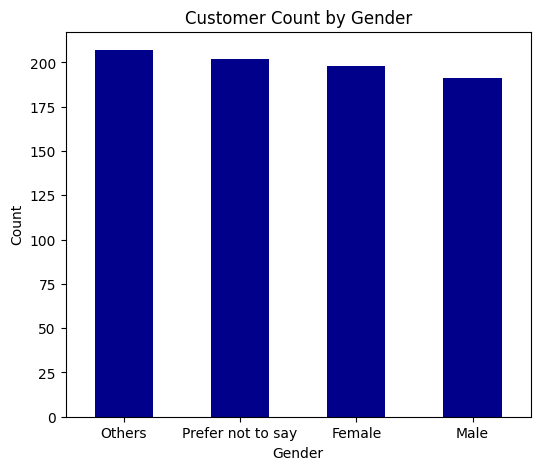


Percentage(%ge) of customers different genders is below
 Gender
Others               25.94
Prefer not to say    25.31
Female               24.81
Male                 23.93
Name: proportion, dtype: float64


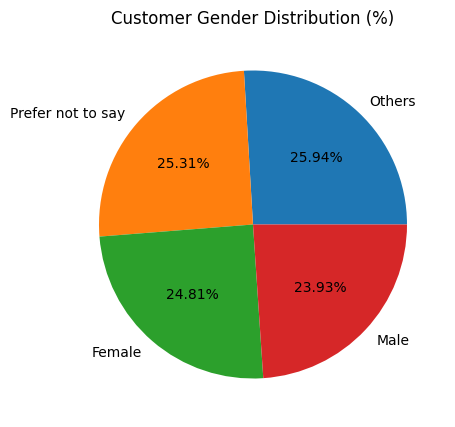

In [16]:
gender_counts=df['Gender'].value_counts()
gender_percentage=df['Gender'].value_counts(normalize=True)*100

print(f'Count of customers different genders is below\n {gender_counts}')

gender_counts.plot(kind='bar', color='darkblue', figsize=(6,5))
plt.title('Customer Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0) 
plt.show()

print(f'\nPercentage(%ge) of customers different genders is below\n {round(gender_percentage,2)}')

labels=gender_percentage.index
percentages=gender_percentage.values

plt.figure(figsize=(5,5))
plt.pie(percentages,labels=labels,autopct='%1.2f%%',startangle=0)
plt.title("Customer Gender Distribution (%)")
plt.show()

#### ● Analyzing overall purchase frequency and most popular product categories.

##### ● Analyzing overall purchase frequency

overall purchase frequency distribution counts as fallows below
Purchase_Frequency
Less than once a month    172
Few times a month         171
Once a month              159
Multiple times a week     148
Once a week               148
Name: count, dtype: int64


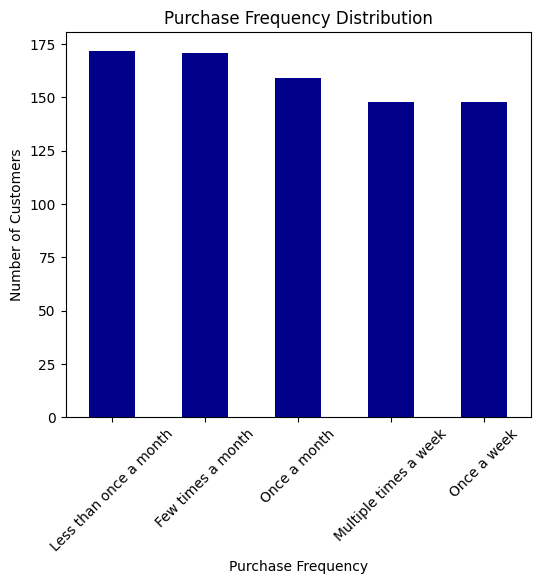

In [17]:
#purchase frequency distribution
print('overall purchase frequency distribution counts as fallows below')
purchase_freq_dist=df['Purchase_Frequency'].value_counts()
print(purchase_freq_dist)

purchase_freq_dist.plot(kind='bar', color='darkblue', figsize=(6,5))
plt.title('Purchase Frequency Distribution')
plt.xlabel('Purchase Frequency')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)  # keep x-axis labels horizontal
plt.show()

Percentage(%ge) distribution of different purchase frequencies are below
Purchase_Frequency
Less than once a month    21.55
Few times a month         21.43
Once a month              19.92
Multiple times a week     18.55
Once a week               18.55
Name: proportion, dtype: float64


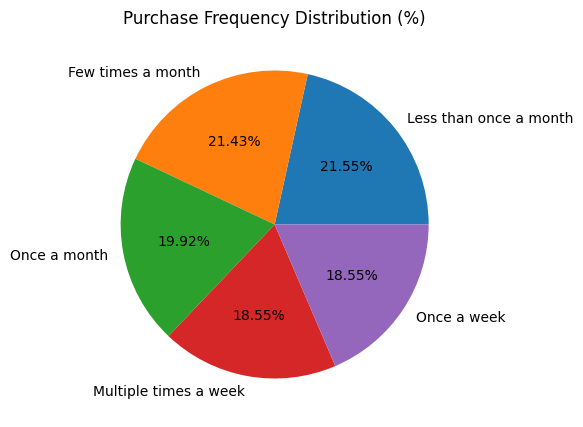

In [18]:
#percentage distribution of different frequencies
print('Percentage(%ge) distribution of different purchase frequencies are below')
purchase_freq_percent=round((df['Purchase_Frequency'].value_counts(normalize=True)*100),2)
print(purchase_freq_percent)

labels=purchase_freq_percent.index
percentages=purchase_freq_percent.values

plt.figure(figsize=(5,5))
plt.pie(percentages,labels=labels,autopct='%1.2f%%',startangle=0)    
plt.title('Purchase Frequency Distribution (%)')
plt.show()

● Analyzing most popular product categories.

In [19]:
#getting all category counts
categories=(df['Purchase_Categories'].str.split(';').explode().str.strip())
category_counts=categories.value_counts()
print('Different product categories and their counts are below')
category_counts

Different product categories and their counts are below


Purchase_Categories
Clothing and Fashion          448
Home and Kitchen              419
Beauty and Personal Care      416
others                        388
Groceries and Gourmet Food    365
Name: count, dtype: int64

##### Top 3 categories

In [20]:
#most popular (top3) categories are obtained in codes below
category_counts=categories.value_counts().head(3)
print('Top 3 product categories and their counts are below : ')
print(category_counts)

Top 3 product categories and their counts are below : 
Purchase_Categories
Clothing and Fashion        448
Home and Kitchen            419
Beauty and Personal Care    416
Name: count, dtype: int64


#### ● Identifying top browsing methods and most common cart abandonment factors.

##### ● Identifying top browsing methods

In [21]:
#top browsing methods
browsing_counts=df['Product_Search_Method'].value_counts()
browsing_percentage=df['Product_Search_Method'].value_counts(normalize=True)*100
print(f'Browing methods and counts are below\n {browsing_counts}')
print('\n')
print(f'Percentage of different Types of browing are below \n {round(browsing_percentage,2)}')

Browing methods and counts are below
 Product_Search_Method
keyword       175
others        164
unknown       160
categories    158
filter        141
Name: count, dtype: int64


Percentage of different Types of browing are below 
 Product_Search_Method
keyword       21.93
others        20.55
unknown       20.05
categories    19.80
filter        17.67
Name: proportion, dtype: float64


##### ● Identifying most common cart abandonment factors.

In [22]:
#cart abandoning factors
abandonment_counts=df['Cart_Abandonment_Factors'].value_counts()
abandonment_percentage=df['Cart_Abandonment_Factors'].value_counts(normalize=True)*100
print(f'Cart abandonment factors and counts are below\n {abandonment_counts}')
print(f'\nCart abandonment reason and their percentage is below\n {round(abandonment_percentage,2)}')

Cart abandonment factors and counts are below
 Cart_Abandonment_Factors
High shipping costs                           208
Changed my mind or no longer need the item    204
others                                        202
Found a better price elsewhere                184
Name: count, dtype: int64

Cart abandonment reason and their percentage is below
 Cart_Abandonment_Factors
High shipping costs                           26.07
Changed my mind or no longer need the item    25.56
others                                        25.31
Found a better price elsewhere                23.06
Name: proportion, dtype: float64


#### ● Calculating mean and median of satisfaction, recommendation helpfulness, and rating accuracy.

##### ● Calculating mean and median of satisfaction

In [23]:
mean_satisfaction=df['Shopping_Satisfaction'].mean()
median_satisfaction=df['Shopping_Satisfaction'].median()

print('Mean Shopping Satisfaction : ',round(mean_satisfaction,2))
print('Median Shopping Satisfaction : ',round(median_satisfaction,2))

Mean Shopping Satisfaction :  2.87
Median Shopping Satisfaction :  3.0


##### ● Calculating mean and median of recommendation helpfulness

In [24]:
mapping={'Yes': 1,'Sometimes': 2,'NO': 3}
df['Rec_Helpfulness_Num']=df['Recommendation_Helpfulness'].map(mapping)

mean_helpfulness=df['Rec_Helpfulness_Num'].mean()
median_helpfulness=df['Rec_Helpfulness_Num'].median()

print('Mean Recommendation Helpfulness : ', round(mean_helpfulness,2))
print('Median Recommendation Helpfulness : ', round(median_helpfulness,2))

Mean Recommendation Helpfulness :  1.49
Median Recommendation Helpfulness :  1.0


##### ● Calculating mean and median of rating accuracy

In [25]:
mean_rating_accuracy=df['Rating_Accuracy'].mean()
median_rating_accuracy=df['Rating_Accuracy'].median()

print('Mean Rating Accuracy : ',round(mean_rating_accuracy,2))
print('Median Rating Accuracy : ',round(median_rating_accuracy,2))

Mean Rating Accuracy :  3.09
Median Rating Accuracy :  3.0


### Customer Segmentation and Profiling

#### ● Segmenting customers based on purchase frequency and shopping satisfaction levels.

In [26]:
df['Purchase_Frequency']=df['Purchase_Frequency'].str.strip().str.title()

In [27]:
high_freq=['Multiple Times A Week', 'Once A Week']
medium_freq=['Few Times A Month', 'Once A Month']
low_freq=['Less Than Once A Month']

In [28]:
satisfaction_high=df['Shopping_Satisfaction'].quantile(0.65)
satisfaction_med=df['Shopping_Satisfaction'].quantile(0.40)

In [29]:
abandonment_reasons=['Found a better price elsewhere','High shipping costs',
                       'Changed my mind or no longer need the item']

df['Is_At_Risk_Abandonment']=df['Cart_Abandonment_Factors'].isin(abandonment_reasons)

In [30]:
def segment_customer(row):
    if (row['Purchase_Frequency'] in high_freq and
        row['Shopping_Satisfaction'] >= satisfaction_high):
        return 'Frequent Buyers'

    elif (row['Purchase_Frequency'] in medium_freq and
          row['Shopping_Satisfaction'] >= satisfaction_med):
        return 'Occasional Shoppers'

    elif (row['Shopping_Satisfaction'] < satisfaction_med or
          row['Is_At_Risk_Abandonment']):
        return 'At-Risk Customers'

    else:
        return 'Other'

In [31]:
df['Customer_Segment']=df.apply(segment_customer, axis=1)

In [32]:
df['Customer_Segment'].value_counts()

Customer_Segment
At-Risk Customers      368
Occasional Shoppers    258
Frequent Buyers        109
Other                   63
Name: count, dtype: int64

#### ● Analyzing demographic or behavioral differences across these segments.

##### ● Age demographic or behavioral differences across segments.

In [33]:
df.groupby('Customer_Segment')['age'].agg(['mean','median','count'])

,mean,median,count
Customer_Segment,,,
At-Risk Customers,36.676630,38.0,368
Frequent Buyers,33.394495,33.0,109
Occasional Shoppers,34.864341,36.5,258
Other,37.857143,41.0,63


##### ● Gender demographic or behavioral differences across segments.

In [34]:
pd.crosstab(df['Customer_Segment'],df['Gender'],normalize='index')*100

Gender,Female,Male,Others,Prefer not to say
Customer_Segment,,,,
At-Risk Customers,25.271739,24.184783,28.532609,22.010870
Frequent Buyers,30.275229,22.935780,24.770642,22.018349
Occasional Shoppers,21.317829,25.193798,22.480620,31.007752
Other,26.984127,19.047619,26.984127,26.984127


##### ● Purchase Category demographic or behavioral differences across segments.

In [35]:
# Create dummy variables for each category
df_expanded=df['Purchase_Categories'].str.get_dummies(sep=';')

In [36]:
df_onehot=pd.concat([df['Customer_Segment'], df_expanded], axis=1)

In [37]:
category_distribution=df_onehot.groupby('Customer_Segment').mean()*100

In [38]:
print(category_distribution)

                     Beauty and Personal Care  Clothing and Fashion  \
Customer_Segment                                                      
At-Risk Customers                   51.358696             55.163043   
Frequent Buyers                     55.963303             57.798165   
Occasional Shoppers                 51.162791             56.589147   
Other                               53.968254             57.142857   

                     Groceries and Gourmet Food  Home and Kitchen     others  
Customer_Segment                                                              
At-Risk Customers                     48.369565         52.717391  50.543478  
Frequent Buyers                       46.788991         59.633028  45.871560  
Occasional Shoppers                   41.085271         51.937984  48.837209  
Other                                 47.619048         41.269841  41.269841  


##### ● Browsing Frequency demographic or behavioral differences across these segments.

In [39]:
pd.crosstab(df['Customer_Segment'],df['Browsing_Frequency'],normalize='index')*100

Browsing_Frequency,Few times a month,Few times a week,Multiple times a day,Rarely
Customer_Segment,,,,
At-Risk Customers,22.826087,25.271739,23.097826,28.804348
Frequent Buyers,25.688073,22.018349,30.275229,22.018349
Occasional Shoppers,26.744186,25.968992,23.643411,23.643411
Other,17.460317,20.634921,31.746032,30.158730


##### ● Product search method demographic or behavioral differences across these segments.

In [40]:
pd.crosstab(df['Customer_Segment'],df['Product_Search_Method'],normalize='index')*100

Product_Search_Method,categories,filter,keyword,others,unknown
Customer_Segment,,,,,
At-Risk Customers,19.293478,20.923913,20.380435,17.119565,22.282609
Frequent Buyers,19.266055,18.348624,25.688073,20.183486,16.513761
Occasional Shoppers,19.379845,14.728682,20.930233,26.356589,18.604651
Other,25.396825,9.523810,28.571429,17.460317,19.047619


##### ● Search result exploration demographic or behavioral differences across these segments.

In [41]:
pd.crosstab(df['Customer_Segment'],df['Search_Result_Exploration'],normalize='index')*100

Search_Result_Exploration,First page,Multiple pages
Customer_Segment,,
At-Risk Customers,50.271739,49.728261
Frequent Buyers,59.633028,40.366972
Occasional Shoppers,53.100775,46.899225
Other,52.380952,47.619048


##### ● Add to Cart Browsing demographic or behavioral differences across these segments.

In [42]:
pd.crosstab(df['Customer_Segment'],df['Add_to_Cart_Browsing'],normalize='index')*100

Add_to_Cart_Browsing,Maybe,No,Yes
Customer_Segment,,,
At-Risk Customers,30.163043,32.880435,36.956522
Frequent Buyers,33.944954,31.192661,34.862385
Occasional Shoppers,32.945736,31.782946,35.271318
Other,28.571429,42.857143,28.571429


##### ● Cart Abandonment Factors demographic or behavioral differences across these segments.

In [43]:
pd.crosstab(df['Customer_Segment'],df['Cart_Abandonment_Factors'],normalize='index')*100

Cart_Abandonment_Factors,Changed my mind or no longer need the item,Found a better price elsewhere,High shipping costs,others
Customer_Segment,,,,
At-Risk Customers,29.347826,23.913043,32.336957,14.402174
Frequent Buyers,26.605505,26.605505,22.935780,23.853211
Occasional Shoppers,25.968992,25.968992,24.806202,23.255814
Other,0.000000,0.000000,0.000000,100.000000


##### ● 'Save for Later' frequency demographic or behavioral differences across these segments.

In [44]:
pd.crosstab(df['Customer_Segment'],df['Saveforlater_Frequency'],normalize='index')*100

Saveforlater_Frequency,Always,Never,Often,Rarely,Sometimes
Customer_Segment,,,,,
At-Risk Customers,19.565217,22.010870,19.293478,19.021739,20.108696
Frequent Buyers,12.844037,19.266055,19.266055,27.522936,21.100917
Occasional Shoppers,25.193798,22.093023,16.279070,14.341085,22.093023
Other,20.634921,23.809524,19.047619,25.396825,11.111111


##### ● Review Participation frequency demographic or behavioral differences across these segments.

In [45]:
pd.crosstab(df['Customer_Segment'],df['Review_Left'],normalize='index')*100

Review_Left,No,Yes
Customer_Segment,,
At-Risk Customers,48.369565,51.630435
Frequent Buyers,45.871560,54.128440
Occasional Shoppers,51.162791,48.837209
Other,41.269841,58.730159


##### ● Review Reliability frequency demographic or behavioral differences across these segments.

In [46]:
pd.crosstab(df['Customer_Segment'],df['Review_Reliability'],normalize='index')*100

Review_Reliability,Heavily,Moderately,Never,Occasionally,Rarely
Customer_Segment,,,,,
At-Risk Customers,16.304348,22.282609,22.282609,17.391304,21.739130
Frequent Buyers,19.266055,17.431193,14.678899,18.348624,30.275229
Occasional Shoppers,22.480620,16.666667,20.542636,18.217054,22.093023
Other,17.460317,23.809524,19.047619,15.873016,23.809524


##### ● Review Helpfulness frequency demographic or behavioral differences across these segments.

In [47]:
pd.crosstab(df['Customer_Segment'],df['Review_Helpfulness'],normalize='index')*100

Review_Helpfulness,No,Sometimes,Yes
Customer_Segment,,,
At-Risk Customers,32.065217,33.423913,34.510870
Frequent Buyers,27.522936,42.201835,30.275229
Occasional Shoppers,29.457364,37.984496,32.558140
Other,42.857143,28.571429,28.571429


##### ● Personalised Rating Frequency demographic or behavioral differences across these segments.

In [48]:
df.groupby('Customer_Segment')['Personalized_Recommendation_Frequency'].agg(['mean','median','count'])

,mean,median,count
Customer_Segment,,,
At-Risk Customers,3.114130,3.0,368
Frequent Buyers,2.963303,3.0,109
Occasional Shoppers,2.941860,3.0,258
Other,2.904762,3.0,63


##### ● Recomendation Helpfullness frequency demographic or behavioral differences across these segments.

In [49]:
pd.crosstab(df['Customer_Segment'],df['Recommendation_Helpfulness'],normalize='index')*100

Recommendation_Helpfulness,No,Sometimes,Yes
Customer_Segment,,,
At-Risk Customers,31.521739,34.782609,33.695652
Frequent Buyers,42.201835,20.183486,37.614679
Occasional Shoppers,34.496124,32.558140,32.945736
Other,39.682540,36.507937,23.809524


#### ● Using clustering (e.g., K-Means) for behavioral grouping based on survey responses.

In [50]:
df_cluster=df.drop(columns=["Timestamp", "transaction"])

In [51]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = [
    'Gender','Browsing_Frequency','Product_Search_Method','Purchase_Frequency','Customer_Segment',
    'Search_Result_Exploration','Add_to_Cart_Browsing','Cart_Completion_Frequency',
    'Cart_Abandonment_Factors','Saveforlater_Frequency','Review_Left','Review_Reliability',
    'Review_Helpfulness','Recommendation_Helpfulness','Service_Appreciation','Improvement_Areas'
]

# Apply LabelEncoder separately for each column
for col in categorical_cols:
    if df_cluster[col].dtype=='object':  # Only encode strings
        le = LabelEncoder()
        df_cluster[col] = le.fit_transform(df_cluster[col])
        
for col in categorical_cols:
    df_cluster[col] = df_cluster[col].fillna(df_cluster[col].mode()[0])

In [52]:
purchase_dummies=df_cluster["Purchase_Categories"].str.get_dummies(sep=";")
df_cluster=pd.concat([df_cluster.drop("Purchase_Categories", axis=1), purchase_dummies], axis=1)

In [53]:
df_cluster=df_cluster.fillna(df_cluster.mean())

In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

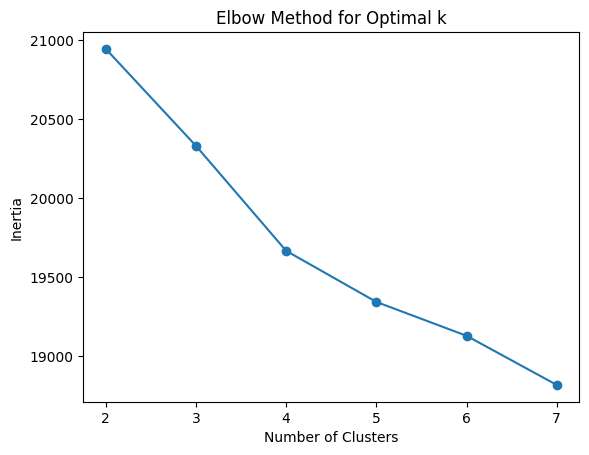

In [55]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure()
plt.plot(range(2, 8), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [56]:
#by elbow curve graph method number of clusters (n_clusters) are taken as 4.
kmeans=KMeans(n_clusters=4,random_state=42)
df["Customer_Segment"]=kmeans.fit_predict(X_scaled)

In [57]:
# Select only numeric columns
numeric_cols=df.select_dtypes(include=["int64", "float64"]).columns

# Group by cluster and compute mean only for numeric columns
cluster_profile = df[numeric_cols].groupby(df["Customer_Segment"]).mean()
print(cluster_profile)

                        age  Customer_Reviews_Importance  \
Customer_Segment                                           
0                 34.960000                     2.980000   
1                 37.301980                     2.871287   
2                 34.685484                     3.040323   
3                 36.040404                     3.085859   

                  Personalized_Recommendation_Frequency  Rating_Accuracy  \
Customer_Segment                                                           
0                                              3.366667         3.320000   
1                                              2.965347         3.183168   
2                                              2.883065         3.032258   
3                                              2.989899         2.878788   

                  Shopping_Satisfaction    transaction  Rec_Helpfulness_Num  
Customer_Segment                                                             
0                         

In [58]:
from sklearn.preprocessing import LabelEncoder

df_profile = df.copy()

categorical_cols = df_profile.select_dtypes(include="object").columns.tolist()

# Exclude 'Customer_Segment' if already present
if "Customer_Segment" in categorical_cols:
    categorical_cols.remove("Customer_Segment")

# Encode categorical columns
for col in categorical_cols:
    le = LabelEncoder()
    df_profile[col] = le.fit_transform(df_profile[col])

# Now groupby and compute mean
cluster_profile = df_profile.groupby("Customer_Segment").mean()
print(cluster_profile)

                                           Timestamp        age    Gender  \
Customer_Segment                                                            
0                2023-06-08 13:26:35.126666752-05:30  34.960000  2.093333   
1                2023-06-08 10:43:21.514851584-05:30  37.301980  1.534653   
2                2023-06-08 10:32:18.036290304-05:30  34.685484  1.278226   
3                2023-06-08 06:31:01.292929280-05:30  36.040404  1.363636   

                  Purchase_Frequency  Purchase_Categories  Browsing_Frequency  \
Customer_Segment                                                                
0                           1.580000            10.926667            1.533333   
1                           1.910891            13.757426            1.698020   
2                           2.080645            15.032258            1.383065   
3                           2.010101            14.126263            1.560606   

                  Product_Search_Method  Search_Re

### Recommendation and Review Insights

#### ● Examining the relationship between 'Recommendation helpfulness' and 'Shopping satisfaction'.

In [59]:
df.groupby('Recommendation_Helpfulness')['Shopping_Satisfaction'] \
  .agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
Recommendation_Helpfulness,,,,
No,276,2.898551,3.0,1.428489
Sometimes,257,2.801556,3.0,1.450861
Yes,265,2.898113,3.0,1.417222


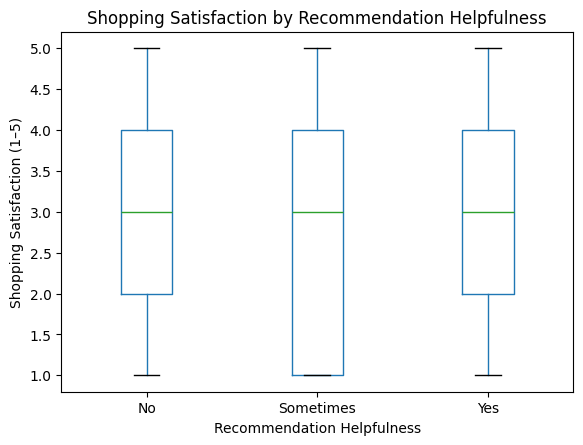

In [60]:
import matplotlib.pyplot as plt

df.boxplot(
    column='Shopping_Satisfaction',
    by='Recommendation_Helpfulness',
    grid=False
)
plt.title('Shopping Satisfaction by Recommendation Helpfulness')
plt.suptitle('')
plt.xlabel('Recommendation Helpfulness')
plt.ylabel('Shopping Satisfaction (1–5)')
plt.show()

In [61]:
from scipy.stats import f_oneway

yes=df[df['Recommendation_Helpfulness']=='Yes']['Shopping_Satisfaction']
no=df[df['Recommendation_Helpfulness']=='No']['Shopping_Satisfaction']
sometimes=df[df['Recommendation_Helpfulness']=='Sometimes']['Shopping_Satisfaction']

f_stat, p_val=f_oneway(yes, no, sometimes)
print('F-statistic:',f_stat)
print('p-value:',p_val)

F-statistic: 0.397904090759471
p-value: 0.6718601506502613


In [62]:
if p_val>=0.5:
    print('No statistically significant difference')
else:
    print('Recommendation helpfulness significantly affects satisfaction')

No statistically significant difference


#### ● Evaluating how 'Review Reliability' and 'Helpfulness' impact 'Overall ratings'.

##### ● Evaluating how 'Review Reliability' impact 'Overall ratings'

In [63]:
reliability_map={'Never': 1,'Rarely': 2,'Occasionally': 3,'Moderately': 4,'Heavily': 5}
df['Review_Reliability_Num']=df['Review_Reliability'].map(reliability_map)

In [64]:
df.groupby('Review_Reliability')['Rating_Accuracy'] \
  .agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
Review_Reliability,,,,
Heavily,150,3.193333,3.0,1.383977
Moderately,159,3.031447,3.0,1.507036
Never,163,2.773006,3.0,1.375718
Occasionally,141,3.219858,3.0,1.352734
Rarely,185,3.221622,3.0,1.425531


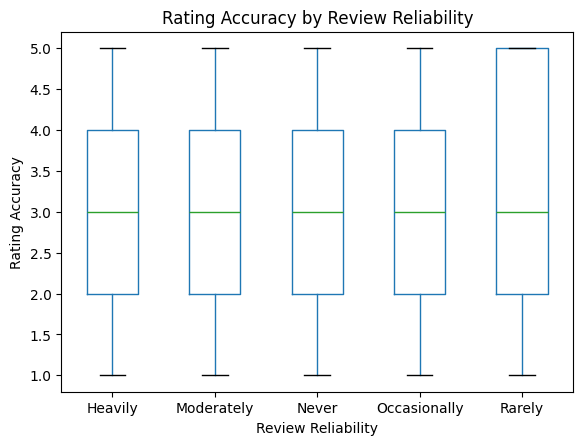

In [65]:
df.boxplot(column='Rating_Accuracy',by='Review_Reliability',grid=False)
plt.title('Rating Accuracy by Review Reliability')
plt.suptitle('')
plt.xlabel('Review Reliability')
plt.ylabel('Rating Accuracy')
plt.show()

In [66]:
heavily=df[df['Review_Reliability']=='Heavily']['Rating_Accuracy']
moderately=df[df['Review_Reliability']=='Moderately']['Rating_Accuracy']
occasionally=df[df['Review_Reliability']=='Occasionally']['Rating_Accuracy']
rarely=df[df['Review_Reliability']=='Rarely']['Rating_Accuracy']
never=df[df['Review_Reliability']=='Never']['Rating_Accuracy']

f_stat, p_val=f_oneway(heavily,moderately,occasionally,rarely,never)
print('F-statistic:',f_stat)
print('p-value:',p_val)

F-statistic: 3.021974966567266
p-value: 0.01726376452339916


In [67]:
if p_val>=0.5:
    print('No statistically significant difference in Overall Ratings')
else:
    print('Review reliability significantly affects Overall Ratings')

Review reliability significantly affects Overall Ratings


##### ● Evaluating how 'Helpfulness' impact 'Overall ratings'

In [68]:
df.groupby('Review_Helpfulness')['Rating_Accuracy'] \
  .agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
Review_Helpfulness,,,,
No,251,3.031873,3.0,1.419500
Sometimes,285,3.073684,3.0,1.455263
Yes,262,3.152672,3.0,1.381172


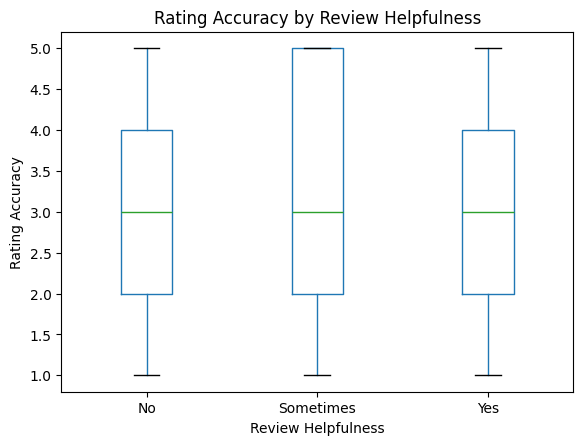

In [69]:
df.boxplot(column='Rating_Accuracy',by='Review_Helpfulness',grid=False)
plt.title('Rating Accuracy by Review Helpfulness')
plt.suptitle('')
plt.xlabel('Review Helpfulness')
plt.ylabel('Rating Accuracy')
plt.show()

In [70]:
yes=df[df['Review_Helpfulness']=='Yes']['Rating_Accuracy']
no=df[df['Review_Helpfulness']=='No']['Rating_Accuracy']
sometimes=df[df['Review_Helpfulness']=='Sometimes']['Rating_Accuracy']

f_stat, p_val=f_oneway(yes, no, sometimes)
print('F-statistic:',f_stat)
print('p-value:',p_val)

F-statistic: 0.48179660329688695
p-value: 0.6178529133405277


In [71]:
if p_val>=0.5:
    print('No statistically significant difference in Overall Ratings')
else:
    print('Review helpfulness significantly affects Overall Ratings')

No statistically significant difference in Overall Ratings


#### ● Identifying trends in how often customers engage with or trust personalized recommendations.

In [72]:
cols=['Gender','Purchase_Categories','Browsing_Frequency','Product_Search_Method','Search_Result_Exploration',
    'Add_to_Cart_Browsing','Cart_Completion_Frequency','Cart_Abandonment_Factors','Saveforlater_Frequency',
    'Review_Left','Review_Reliability','Review_Helpfulness','Recommendation_Helpfulness','Service_Appreciation',
    'Improvement_Areas']

df_cat=df[cols].copy()

In [73]:
transactions=df_cat.apply(lambda row: [f"{col}={row[col]}" for col in df_cat.columns],axis=1).tolist()

In [74]:
from mlxtend.preprocessing import TransactionEncoder

te=TransactionEncoder()
te_array=te.fit(transactions).transform(transactions)

df_encoded = pd.DataFrame(te_array, columns=te.columns_)

In [75]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets=apriori(
    df_encoded,
    min_support=0.1,   # adjust if dataset is small/large
    use_colnames=True)

In [76]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.3
)

In [77]:
rec_rules = rules[
    rules['consequents'].astype(str).str.contains('Recommendation_Helpfulness')
].sort_values(by='lift', ascending=False)

rec_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

,antecedents,consequents,support,confidence,lift
142,(Review_Left=No),(Recommendation_Helpfulness=Sometimes),0.181704,0.375648,1.166408
154,(Review_Left=Yes),(Recommendation_Helpfulness=Yes),0.196742,0.381068,1.147518
212,"(Search_Result_Exploration=First page, Review_...",(Recommendation_Helpfulness=Yes),0.106516,0.379464,1.142689
122,(Review_Helpfulness=No),(Recommendation_Helpfulness=No),0.117794,0.374502,1.082799
151,(Review_Helpfulness=Yes),(Recommendation_Helpfulness=Yes),0.117794,0.358779,1.080398
18,(Add_to_Cart_Browsing=No),(Recommendation_Helpfulness=Sometimes),0.112782,0.340909,1.058543
0,(Add_to_Cart_Browsing=Maybe),(Recommendation_Helpfulness=No),0.112782,0.358566,1.036723
158,(Search_Result_Exploration=Multiple pages),(Recommendation_Helpfulness=Yes),0.162907,0.343915,1.035639
144,(Search_Result_Exploration=First page),(Recommendation_Helpfulness=Sometimes),0.174185,0.330952,1.027626
136,(Review_Helpfulness=No),(Recommendation_Helpfulness=Sometimes),0.104010,0.330677,1.026772


### Visualization and Reporting

#### ○ Purchase categories visuals

In [89]:
#getting all category counts
categories=(df['Purchase_Categories'].str.split(';').explode().str.strip())
category_counts=categories.value_counts()

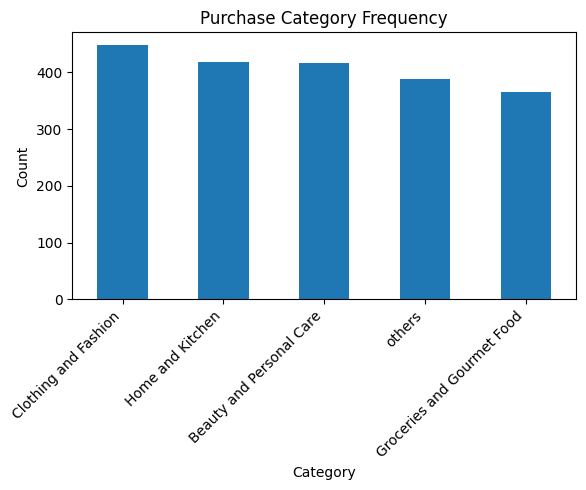

In [79]:
plt.figure(figsize=(6,5))
category_counts.plot(kind="bar")
plt.title("Purchase Category Frequency")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

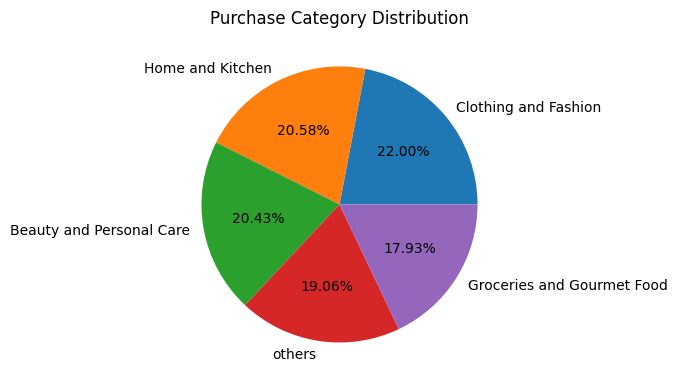

In [88]:
plt.figure(figsize=(6,5))
category_counts.plot(kind="pie", autopct="%1.2f%%")
plt.title("Purchase Category Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

#### ○ Browsing frequency distribution visuals

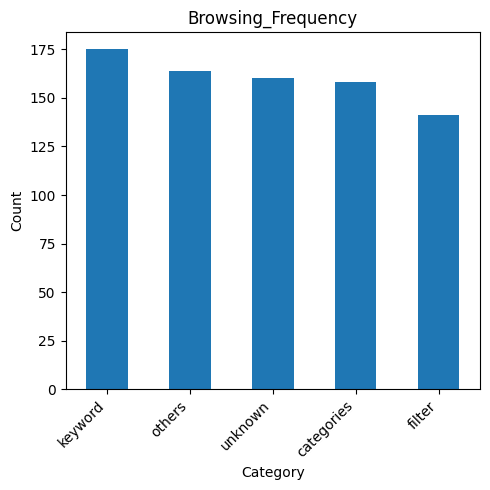

In [81]:
plt.figure(figsize=(5,5))
browsing_counts.plot(kind="bar")
plt.title("Browsing_Frequency")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

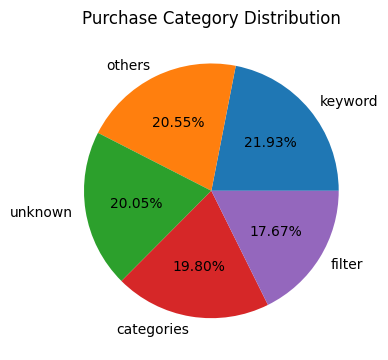

In [82]:
plt.figure(figsize=(4,5))
browsing_percentage.plot(kind="pie", autopct="%1.2f%%")
plt.title("Purchase Category Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

#### ○ Satisfaction(Shopping saticifaction) levels Visuals

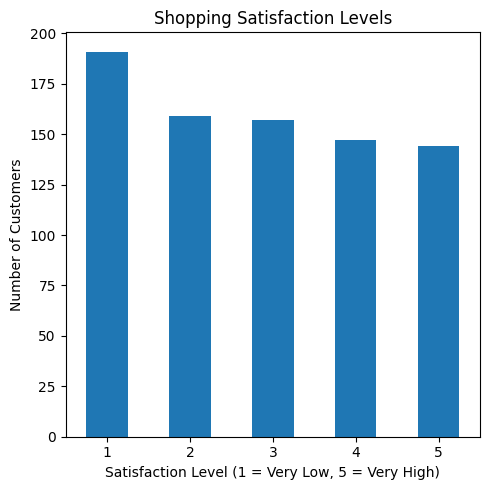

In [83]:
satisfaction_counts=(df["Shopping_Satisfaction"].value_counts().sort_index())

plt.figure(figsize=(5,5))
satisfaction_counts.plot(kind="bar")
plt.title("Shopping Satisfaction Levels")
plt.xlabel("Satisfaction Level (1 = Very Low, 5 = Very High)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

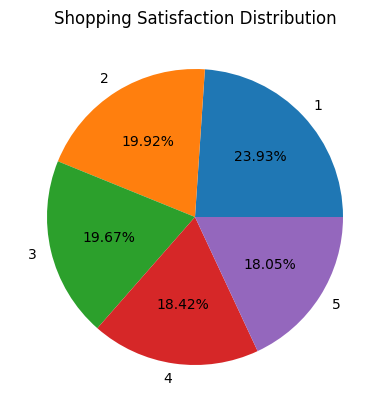

In [84]:
plt.figure(figsize=(4,5))
satisfaction_counts.plot(kind="pie", autopct="%1.2f%%")
plt.title("Shopping Satisfaction Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

#### ○ Correlation between recommendation usefulness and satisfaction Visuals using 'heatmap'

In [85]:
helpfulness_map = {'No': 0,'Sometimes': 1,'Yes': 2}
df["Recommendation_Helpfulness_Num"]=(df["Recommendation_Helpfulness"].map(helpfulness_map))

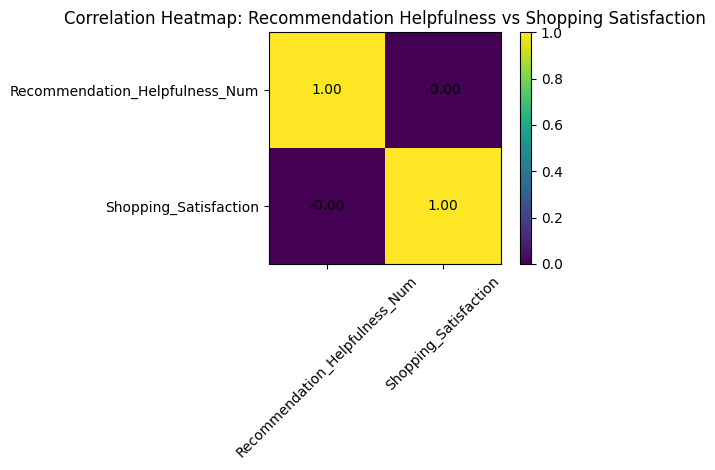

In [86]:
corr_data=df[['Recommendation_Helpfulness_Num','Shopping_Satisfaction']]

# Compute correlation matrix
corr_matrix=corr_data.corr()

# Create heatmap
plt.figure()
plt.imshow(corr_matrix)
plt.colorbar()

# Axis labels
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

# Add correlation values inside cells
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Heatmap: Recommendation Helpfulness vs Shopping Satisfaction")
plt.tight_layout()
plt.show()

In [ ]:
#The Link for video is below:
# https://drive.google.com/file/d/1CPXNAmr8d2zG2Z0hXUb7LGqrrS2Ewi38/view?usp=sharing